# ShopEase — Exploratory Data Analysis

## Objective

Analyze e-commerce sales performance, customer purchasing patterns,
product categories, and revenue trends using the cleaned ShopEase dataset.

In [2]:
# import the required libraries

import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt

In [3]:
sales = pd.read_csv(
    "../data/processed/sales_analysis.csv",
    parse_dates = ["orders_date", "signup_date"]
)

print("Dataset loaded successfully!")

print("Shape : ",sales.shape)

Dataset loaded successfully!
Shape :  (49925, 26)


In [4]:
sales.head()

,order_item_id,order_id,product_id,quantity,unit_price,discount,gross_amount,discount_amount,total_amount,customer_id,...,price,cost,profit_per_unit,first_name,last_name,gender,age,city,country,signup_date
0,OI000001,O00001,P00302,3,752.24,5,2256.72,112.84,2143.88,C02846,...,752.24,592.38,159.86,Sara,Thomas,Female,19,Dubai,UAE,2025-09-02
1,OI000002,O00001,P00437,1,1608.19,5,1608.19,80.41,1527.78,C02846,...,1608.19,838.85,769.34,Sara,Thomas,Female,19,Dubai,UAE,2025-09-02
2,OI000003,O00002,P00188,4,405.26,10,1621.04,162.10,1458.94,C00980,...,405.26,265.84,139.42,Ali,Martin,Male,36,Dubai,UAE,2025-04-08
3,OI000004,O00002,P00446,3,328.41,0,985.23,0.00,985.23,C00980,...,328.41,193.30,135.11,Ali,Martin,Male,36,Dubai,UAE,2025-04-08
4,OI000005,O00002,P00392,5,1258.14,0,6290.70,0.00,6290.70,C00980,...,1258.14,762.86,495.28,Ali,Martin,Male,36,Dubai,UAE,2025-04-08


In [5]:
sales.describe()

,quantity,unit_price,discount,gross_amount,discount_amount,total_amount,orders_date,price,cost,profit_per_unit,age,signup_date
count,49925.000000,49925.000000,49925.000000,49925.000000,49925.000000,49925.000000,49925,49925.000000,49925.000000,49925.000000,49925.000000,49925
mean,2.999119,978.485201,5.003005,2935.388949,146.723503,2788.665446,2025-12-10 20:08:31.967952,978.485201,630.996270,347.488932,40.862053,2025-03-22 15:42:16.837255
min,1.000000,22.060000,0.000000,22.060000,0.000000,17.650000,2024-01-07 00:00:00,22.060000,15.570000,6.490000,18.000000,2024-01-01 00:00:00
25%,2.000000,511.520000,0.000000,1049.270000,0.000000,997.670000,2025-08-01 00:00:00,511.520000,334.080000,168.120000,29.000000,2024-08-06 00:00:00
50%,3.000000,948.360000,0.000000,2293.300000,0.000000,2155.090000,2026-02-06 00:00:00,948.360000,599.080000,331.070000,41.000000,2025-03-20 00:00:00
75%,4.000000,1456.690000,10.000000,4312.140000,193.230000,4066.410000,2026-06-06 00:00:00,1456.690000,923.830000,502.710000,52.000000,2025-11-01 00:00:00
max,5.000000,1980.930000,20.000000,9904.650000,1980.930000,9904.650000,2026-08-30 00:00:00,1980.930000,1532.240000,954.260000,64.000000,2026-06-29 00:00:00
std,1.415219,571.277118,6.137854,2348.390054,258.924176,2243.876401,NaN,571.277118,381.567027,226.080259,13.686725,NaN


In [6]:
print("Total Rows : ",len(sales))

print(
    "Unique orders : ",
    sales["order_id"].nunique()
)

print(
    "Unique customers : ",
    sales["customer_id"].nunique()
)

print(
    "Unique products : ",
    sales["product_id"].nunique()
)

Total Rows :  49925
Unique orders :  20000
Unique customers :  4894
Unique products :  500


In [7]:
sales.head()

,order_item_id,order_id,product_id,quantity,unit_price,discount,gross_amount,discount_amount,total_amount,customer_id,...,price,cost,profit_per_unit,first_name,last_name,gender,age,city,country,signup_date
0,OI000001,O00001,P00302,3,752.24,5,2256.72,112.84,2143.88,C02846,...,752.24,592.38,159.86,Sara,Thomas,Female,19,Dubai,UAE,2025-09-02
1,OI000002,O00001,P00437,1,1608.19,5,1608.19,80.41,1527.78,C02846,...,1608.19,838.85,769.34,Sara,Thomas,Female,19,Dubai,UAE,2025-09-02
2,OI000003,O00002,P00188,4,405.26,10,1621.04,162.10,1458.94,C00980,...,405.26,265.84,139.42,Ali,Martin,Male,36,Dubai,UAE,2025-04-08
3,OI000004,O00002,P00446,3,328.41,0,985.23,0.00,985.23,C00980,...,328.41,193.30,135.11,Ali,Martin,Male,36,Dubai,UAE,2025-04-08
4,OI000005,O00002,P00392,5,1258.14,0,6290.70,0.00,6290.70,C00980,...,1258.14,762.86,495.28,Ali,Martin,Male,36,Dubai,UAE,2025-04-08


In [8]:
# Total Revenue 

# how much sales value was generated ?

total_revenue = sales["total_amount"].sum()

print("Total recorded order value : ",round(total_revenue,2))

Total recorded order value :  139224122.38


In [9]:
# Total Orders

# How many distinct orders were placed?

total_order = sales["order_id"].nunique()

print("Total orders : ",total_order)

Total orders :  20000


In [10]:
# Calculate Average Order Value (AOV)

aov = total_revenue / total_order

print("Average Order Value : ",round(aov,2))

Average Order Value :  6961.21


In [11]:
print("=============== ShopEase Business KPIs ===============")

print(f"Total Recorded order value : AED {total_revenue:,.2f}")

print(f"Total_order : {total_order:,}")

print(f"Average order value : AED {aov:,.2f}")

=============== ShopEase Business KPIs ===============
Total Recorded order value : AED 139,224,122.38
Total_order : 20,000
Average order value : AED 6,961.21


In [12]:
# Calculate Completed Sales Revenue

# Create a Delivered-only DataFrame

delivered_sales = sales[sales["order_status"] == "Delivered"].copy()

print("Delivered order-item rows : ",len(delivered_sales))

Delivered order-item rows :  42276


In [13]:
delivered_sales.head()

,order_item_id,order_id,product_id,quantity,unit_price,discount,gross_amount,discount_amount,total_amount,customer_id,...,price,cost,profit_per_unit,first_name,last_name,gender,age,city,country,signup_date
0,OI000001,O00001,P00302,3,752.24,5,2256.72,112.84,2143.88,C02846,...,752.24,592.38,159.86,Sara,Thomas,Female,19,Dubai,UAE,2025-09-02
1,OI000002,O00001,P00437,1,1608.19,5,1608.19,80.41,1527.78,C02846,...,1608.19,838.85,769.34,Sara,Thomas,Female,19,Dubai,UAE,2025-09-02
2,OI000003,O00002,P00188,4,405.26,10,1621.04,162.10,1458.94,C00980,...,405.26,265.84,139.42,Ali,Martin,Male,36,Dubai,UAE,2025-04-08
3,OI000004,O00002,P00446,3,328.41,0,985.23,0.00,985.23,C00980,...,328.41,193.30,135.11,Ali,Martin,Male,36,Dubai,UAE,2025-04-08
4,OI000005,O00002,P00392,5,1258.14,0,6290.70,0.00,6290.70,C00980,...,1258.14,762.86,495.28,Ali,Martin,Male,36,Dubai,UAE,2025-04-08


In [14]:
# Calculate completed sales revenue

completed_revenue = delivered_sales["total_amount"].sum()

print(
    f"completed sales revenue : AED {completed_revenue:,.2f}"
)

completed sales revenue : AED 118,040,937.28


In [15]:
# Calculate completed orders

completed_orders = delivered_sales["order_id"].nunique()

print(f"Total completed order : {completed_orders}")

Total completed order : 16936


In [16]:
# Calculate completed Average Order Value

completed_aov = completed_revenue / completed_orders

print(f"Completed AOV : AED {completed_aov:,.2f}")

Completed AOV : AED 6,969.82


In [17]:
completion_rate = (completed_orders/total_order) * 100

print(f"Order Completion Rate : {completion_rate:.2f}%")

Order Completion Rate : 84.68%


In [18]:
# Monthly Sales Trend Analysis
# We need to group transactions by month.
# This is called time-series analysis.

# Inspect the available date range

print("First order date:", sales["orders_date"].min())

print("Last order date:", sales["orders_date"].max())

print("Date column type:", sales["orders_date"].dtype)

First order date: 2024-01-07 00:00:00
Last order date: 2026-08-30 00:00:00
Date column type: datetime64[us]


In [19]:
# Extract the month from each order date

delivered_sales["order_month"] = (
    delivered_sales["orders_date"].dt.to_period("M")
)

display(
    delivered_sales[
        ["order_id","orders_date","order_month"]
    ].head(10)
)

,order_id,orders_date,order_month
0,O00001,2025-11-28,2025-11
1,O00001,2025-11-28,2025-11
2,O00002,2025-07-02,2025-07
3,O00002,2025-07-02,2025-07
4,O00002,2025-07-02,2025-07
5,O00003,2024-10-29,2024-10
6,O00003,2024-10-29,2024-10
7,O00004,2026-02-24,2026-02
8,O00004,2026-02-24,2026-02
9,O00005,2025-07-16,2025-07


In [20]:
# Monthly Sales 

monthly_sales = (
    delivered_sales.groupby("order_month")["total_amount"]
    .sum()
    .round(2)
    .reset_index(name="month_revenue")
)

In [21]:
display(monthly_sales)

,order_month,month_revenue
0,2024-01,70798.47
1,2024-02,165308.93
2,2024-03,241625.33
3,2024-04,501411.18
4,2024-05,698326.93
5,2024-06,794205.00
6,2024-07,986102.46
7,2024-08,1271183.82
8,2024-09,1304854.73
9,2024-10,1334061.87


In [22]:
# Validate the monthly revenue calculation

print("Monthly revenue total : ",round(monthly_sales["month_revenue"].sum(),2))

print("original completed revenue : ",round(completed_revenue,2))

print("Revenue matches : ",abs(
    monthly_sales["month_revenue"].sum() - completed_revenue
) < 0.01
)

Monthly revenue total :  118040937.28
original completed revenue :  118040937.28
Revenue matches :  True


In [23]:
monthly_sales.dtypes

order_month      period[M]
month_revenue      float64
dtype: object

# First Sales Visualization

In [24]:
# First Sales Visualization

# Prepare the dates for plotting

monthly_sales["month_date"] = (
    monthly_sales["order_month"].dt.to_timestamp()
)

display(monthly_sales.head())

,order_month,month_revenue,month_date
0,2024-01,70798.47,2024-01-01
1,2024-02,165308.93,2024-02-01
2,2024-03,241625.33,2024-03-01
3,2024-04,501411.18,2024-04-01
4,2024-05,698326.93,2024-05-01


In [25]:
print(monthly_sales.head(12))
print("Shape:", monthly_sales.shape)
print("Minimum:", monthly_sales["month_revenue"].min())
print("Maximum:", monthly_sales["month_revenue"].max())

   order_month  month_revenue month_date
0      2024-01       70798.47 2024-01-01
1      2024-02      165308.93 2024-02-01
2      2024-03      241625.33 2024-03-01
3      2024-04      501411.18 2024-04-01
4      2024-05      698326.93 2024-05-01
5      2024-06      794205.00 2024-06-01
6      2024-07      986102.46 2024-07-01
7      2024-08     1271183.82 2024-08-01
8      2024-09     1304854.73 2024-09-01
9      2024-10     1334061.87 2024-10-01
10     2024-11     1682483.15 2024-11-01
11     2024-12     1661986.02 2024-12-01
Shape: (32, 3)
Minimum: 70798.47
Maximum: 10929972.87


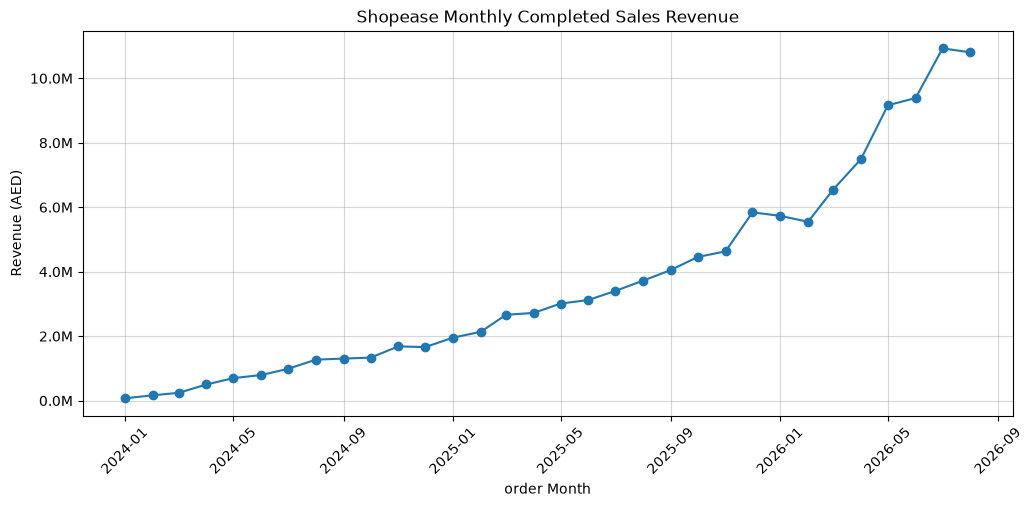

In [26]:
from matplotlib.ticker import FuncFormatter

plt.figure(figsize=(12,5))

plt.plot(
    monthly_sales["month_date"],
    monthly_sales["month_revenue"],
    marker = "o"
)

plt.title("Shopease Monthly Completed Sales Revenue")

plt.xlabel("order Month")

plt.ylabel("Revenue (AED)")

# Convert Y-axis labels to millions
plt.gca().yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{x/1_000_000:.1f}M")
)

plt.xticks(rotation = 45)

plt.grid(True,alpha = 0.5)

plt.show()

In [27]:
# Identify the highest and lowest revenue months using Pandas

highest_month = monthly_sales.loc[
    monthly_sales["month_revenue"].idxmax()
]

lowest_month = monthly_sales.loc[
    monthly_sales["month_revenue"].idxmin()
]

print("Highest revenue month:")
print(highest_month[["order_month", "month_revenue"]])

print("\nLowest revenue month:")
print(lowest_month[["order_month", "month_revenue"]])

Highest revenue month:
order_month          2026-07
month_revenue    10929972.87
Name: 30, dtype: object

Lowest revenue month:
order_month       2024-01
month_revenue    70798.47
Name: 0, dtype: object


# Month-over-Month (MoM) Revenue Growth

In [28]:
# Month-over-Month (MoM) Revenue Growth

# Calculate monthly revenue growth

monthly_sales["mom_growth"] = (
    monthly_sales["month_revenue"].pct_change(fill_method = None) * 100
).round(2)

display(monthly_sales.head())

,order_month,month_revenue,month_date,mom_growth
0,2024-01,70798.47,2024-01-01,NaN
1,2024-02,165308.93,2024-02-01,133.49
2,2024-03,241625.33,2024-03-01,46.17
3,2024-04,501411.18,2024-04-01,107.52
4,2024-05,698326.93,2024-05-01,39.27


In [29]:
# Display the complete growth table

display(
    monthly_sales[
        [
            "order_month",
            "month_revenue",
            "mom_growth"
        ]
    ]
)

,order_month,month_revenue,mom_growth
0,2024-01,70798.47,NaN
1,2024-02,165308.93,133.49
2,2024-03,241625.33,46.17
3,2024-04,501411.18,107.52
4,2024-05,698326.93,39.27
5,2024-06,794205.00,13.73
6,2024-07,986102.46,24.16
7,2024-08,1271183.82,28.91
8,2024-09,1304854.73,2.65
9,2024-10,1334061.87,2.24


In [30]:
# Identify the highest and lowest growth months

highest_growth = monthly_sales.loc[
    monthly_sales["mom_growth"].idxmax()
]

lowest_growth = monthly_sales.loc[
    monthly_sales["mom_growth"].idxmin()
]

print("Highest MoM growth:")
print(highest_growth[["order_month", "mom_growth"]])

print("\nLowest MoM growth:")
print(lowest_growth[["order_month", "mom_growth"]])

Highest MoM growth:
order_month    2024-02
mom_growth      133.49
Name: 1, dtype: object

Lowest MoM growth:
order_month    2026-02
mom_growth       -3.18
Name: 25, dtype: object


In [31]:
# Count the months with positive and negative growth

positive_months = (
    monthly_sales["mom_growth"] > 0
).sum()

negative_months = (
    monthly_sales["mom_growth"] < 0
).sum()

print("Months with positive growth:", positive_months)

print("Months with negative growth:", negative_months)

Months with positive growth: 27
Months with negative growth: 4


# Visualizing Monthly Revenue Growth

In [32]:
# Visualizing Monthly Revenue Growth

# Prepare the chart data

'''
    We already have monthly_sales, containing:
        - order_month
        - month_revenue
        - mom_growth
        - month_date
    First, remove the row where MoM growth is unavailable.
'''

growth_data = monthly_sales.dropna(
    subset = ["mom_growth"]
).copy()

print("Original rows : ",len(monthly_sales))
print("Growth rows : ",len(growth_data))

Original rows :  32
Growth rows :  31


In [33]:
display(growth_data.head())

,order_month,month_revenue,month_date,mom_growth
1,2024-02,165308.93,2024-02-01,133.49
2,2024-03,241625.33,2024-03-01,46.17
3,2024-04,501411.18,2024-04-01,107.52
4,2024-05,698326.93,2024-05-01,39.27
5,2024-06,794205.00,2024-06-01,13.73


In [34]:
growth_data.dtypes

order_month           period[M]
month_revenue           float64
month_date       datetime64[us]
mom_growth              float64
dtype: object

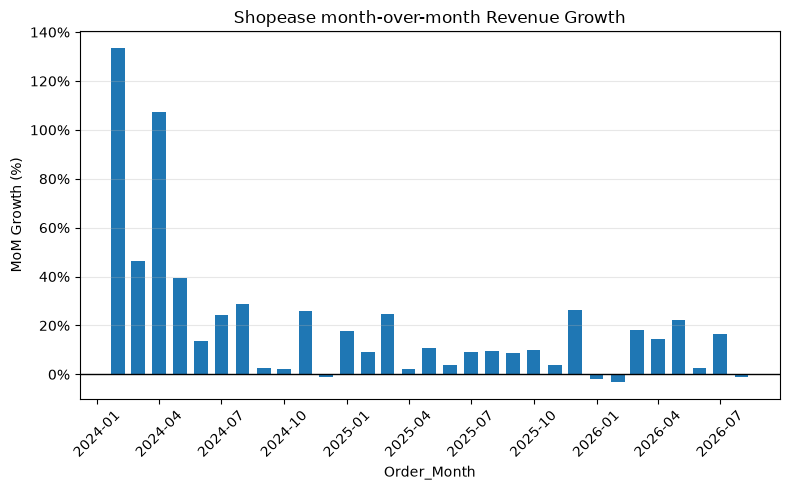

In [35]:
plt.figure(figsize=(8,5))

plt.bar(
    growth_data["month_date"],
    growth_data["mom_growth"],
    width=20
)

plt.axhline(
    y = 0,
    color = "black",
    linewidth = 1
)

# Convert Y-axis labels to millions
plt.gca().yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{round(x)}%")
)

plt.title("Shopease month-over-month Revenue Growth")

plt.xlabel("Order_Month")

plt.ylabel("MoM Growth (%)")

plt.xticks(rotation = 45)

plt.grid(axis = "y",alpha = 0.3)

plt.tight_layout()

In [36]:
# Identify the four declining months

declining_months = growth_data[
    growth_data["mom_growth"] < 0
]

display(
    declining_months[
        ["order_month", "month_revenue", "mom_growth"]
    ]
)

,order_month,month_revenue,mom_growth
11,2024-12,1661986.02,-1.22
24,2026-01,5732040.37,-1.88
25,2026-02,5549783.47,-3.18
31,2026-08,10805508.29,-1.14


# Product Category Revenue Analysis

In [37]:
# Product Category Revenue Analysis

# Which product category contributes the most revenue to ShopEase?   This is called category performance analysis.

# Inspect the available product categories

print("Number of categories:", sales["category"].nunique())

print("\nAvailable categories:")
print(sales["category"].unique())

Number of categories: 5

Available categories:
<StringArray>
['Electronics', 'Beauty', 'Sports', 'Fashion', 'Home']
Length: 5, dtype: str


In [38]:
delivered_sales.head()

,order_item_id,order_id,product_id,quantity,unit_price,discount,gross_amount,discount_amount,total_amount,customer_id,...,cost,profit_per_unit,first_name,last_name,gender,age,city,country,signup_date,order_month
0,OI000001,O00001,P00302,3,752.24,5,2256.72,112.84,2143.88,C02846,...,592.38,159.86,Sara,Thomas,Female,19,Dubai,UAE,2025-09-02,2025-11
1,OI000002,O00001,P00437,1,1608.19,5,1608.19,80.41,1527.78,C02846,...,838.85,769.34,Sara,Thomas,Female,19,Dubai,UAE,2025-09-02,2025-11
2,OI000003,O00002,P00188,4,405.26,10,1621.04,162.10,1458.94,C00980,...,265.84,139.42,Ali,Martin,Male,36,Dubai,UAE,2025-04-08,2025-07
3,OI000004,O00002,P00446,3,328.41,0,985.23,0.00,985.23,C00980,...,193.30,135.11,Ali,Martin,Male,36,Dubai,UAE,2025-04-08,2025-07
4,OI000005,O00002,P00392,5,1258.14,0,6290.70,0.00,6290.70,C00980,...,762.86,495.28,Ali,Martin,Male,36,Dubai,UAE,2025-04-08,2025-07


In [39]:
# Calculate completed revenue by category

category_revenue = (
    delivered_sales.groupby("category")["total_amount"]
    .sum()
    .round(2)
    .reset_index(name="category_revenue")
)

display(category_revenue)

,category,category_revenue
0,Beauty,23975841.41
1,Electronics,23560697.59
2,Fashion,23339171.14
3,Home,22348264.76
4,Sports,24816962.38


In [40]:
# Rank categories from highest to lowest revenue

category_revenue = category_revenue.sort_values(
    by="category_revenue",
    ascending=False
).reset_index(drop=True)

display(category_revenue)

,category,category_revenue
0,Sports,24816962.38
1,Beauty,23975841.41
2,Electronics,23560697.59
3,Fashion,23339171.14
4,Home,22348264.76


# Validate the category revenue total

This is important!

Grouping revenue by category should not change our total completed revenue.

In [41]:
print(
    "Total category revenue:",
    round(category_revenue["category_revenue"].sum(), 2)
)

print(
    "Completed sales revenue:",
    round(completed_revenue, 2)
)

print(
    "Revenue matches:",
    abs(
        category_revenue["category_revenue"].sum()
        - completed_revenue
    ) < 0.01
)

Total category revenue: 118040937.28
Completed sales revenue: 118040937.28
Revenue matches: True


# L-22 Category Revenue Contribution and Visualization

We already know Sports generated the highest revenue.

But imagine a question like :

What percentage of ShopEase's total completed revenue comes from Sports?

This is called revenue contribution analysis.

In [42]:
category_revenue["revenue_share"] = (
    category_revenue["category_revenue"] / completed_revenue * 100
).round(2)

display(category_revenue)

,category,category_revenue,revenue_share
0,Sports,24816962.38,21.02
1,Beauty,23975841.41,20.31
2,Electronics,23560697.59,19.96
3,Fashion,23339171.14,19.77
4,Home,22348264.76,18.93


# Validate the contribution percentages

In [43]:
print(
    f"Total contribution : {category_revenue["revenue_share"].round().sum()}%"
)

Total contribution : 100.0%


# Create a horizontal bar chart

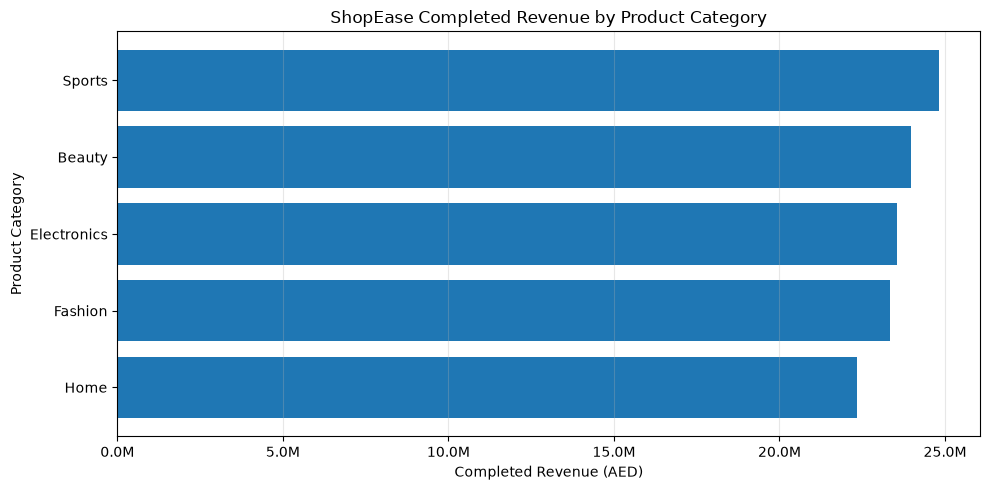

In [44]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.barh(
    category_revenue["category"],
    category_revenue["category_revenue"]
)

plt.title("ShopEase Completed Revenue by Product Category")

plt.xlabel("Completed Revenue (AED)")
plt.ylabel("Product Category")

plt.gca().xaxis.set_major_formatter(
    FuncFormatter(lambda x,pos : f"{x/1_000_000:.1f}M")
)

plt.gca().invert_yaxis()

plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

In [45]:
category_revenue.head()

,category,category_revenue,revenue_share
0,Sports,24816962.38,21.02
1,Beauty,23975841.41,20.31
2,Electronics,23560697.59,19.96
3,Fashion,23339171.14,19.77
4,Home,22348264.76,18.93


In [46]:
# Identify the highest-contributing category automatically

top_category = category_revenue.iloc[0]

print("Top category:", top_category["category"])

print(
    f"Revenue: AED {top_category['category_revenue']:,.2f}"
)

print(
    f"Revenue contribution: {top_category['revenue_share']:.2f}%"
)

Top category: Sports
Revenue: AED 24,816,962.38
Revenue contribution: 21.02%


# L-23  Product Category Sales Volume Analysis

In [47]:
delivered_sales.tail()

,order_item_id,order_id,product_id,quantity,unit_price,discount,gross_amount,discount_amount,total_amount,customer_id,...,cost,profit_per_unit,first_name,last_name,gender,age,city,country,signup_date,order_month
49920,OI049921,O19997,P00039,5,644.33,0,3221.65,0.00,3221.65,C04175,...,475.41,168.92,Fatima,Hassan,Male,42,Sharjah,UAE,2025-03-05,2025-10
49921,OI049922,O19998,P00044,2,347.65,0,695.30,0.00,695.30,C04039,...,259.23,88.42,Mohammed,Johnson,Male,52,Dubai,UAE,2024-06-25,2026-06
49922,OI049923,O19999,P00145,4,108.51,5,434.04,21.70,412.34,C04214,...,74.39,34.12,Emma,Moore,Male,46,Dubai,UAE,2024-04-01,2024-07
49923,OI049924,O19999,P00017,3,486.88,15,1460.64,219.10,1241.54,C04214,...,369.27,117.61,Emma,Moore,Male,46,Dubai,UAE,2024-04-01,2024-07
49924,OI049925,O20000,P00121,5,175.57,5,877.85,43.89,833.96,C03595,...,95.61,79.96,Fatima,Williams,Male,18,Abu Dhabi,UAE,2025-10-06,2026-07


In [48]:
display(
    delivered_sales[
        ["order_id", "product_name", "category", "quantity"]
    ].head(10)
)

,order_id,product_name,category,quantity
0,O00001,Headphones Product 302,Electronics,3
1,O00001,Smartphones Product 437,Electronics,1
2,O00002,Headphones Product 188,Electronics,4
3,O00002,Accessories Product 446,Electronics,3
4,O00002,Skincare Product 392,Beauty,5
5,O00003,Sportswear Product 423,Sports,2
6,O00003,Shoes Product 86,Fashion,5
7,O00004,Clothing Product 218,Fashion,3
8,O00004,Equipment Product 241,Sports,1
9,O00005,Equipment Product 24,Sports,1


In [49]:
category_units = (delivered_sales.groupby("category")["quantity"]
                  .sum()
                  .reset_index(name="unit_sold"))

In [50]:
category_units.head()

,category,unit_sold
0,Beauty,25036
1,Electronics,25250
2,Fashion,26164
3,Home,22148
4,Sports,28423


In [51]:
category_units["unit_sold"].sum()

np.int64(127021)

In [52]:
delivered_sales.groupby("category")["quantity"].sum()

category
Beauty         25036
Electronics    25250
Fashion        26164
Home           22148
Sports         28423
Name: quantity, dtype: int64

In [53]:
category_units = category_units.sort_values(
    by = "unit_sold",
    ascending = False
).reset_index(drop = True)

display(category_units)

,category,unit_sold
0,Sports,28423
1,Fashion,26164
2,Electronics,25250
3,Beauty,25036
4,Home,22148


In [54]:
total_category_units = category_units["unit_sold"].sum()

total_delivered_units = delivered_sales["quantity"].sum()

print("Total category units : ",total_category_units)

print("Total delivered units : ",total_delivered_units)

print(
    "units match : ",
    total_category_units == total_delivered_units
)

Total category units :  127021
Total delivered units :  127021
units match :  True


In [55]:
top_units_category = category_units.iloc[0]

print("Highest-selling category:", top_units_category["category"])

print("Units sold:", top_units_category["unit_sold"])

Highest-selling category: Sports
Units sold: 28423


# L-24 Category Performance Analysis

In [56]:
# from L 22
display(category_revenue.head())

# from L 23
display(category_units.head())

,category,category_revenue,revenue_share
0,Sports,24816962.38,21.02
1,Beauty,23975841.41,20.31
2,Electronics,23560697.59,19.96
3,Fashion,23339171.14,19.77
4,Home,22348264.76,18.93


,category,unit_sold
0,Sports,28423
1,Fashion,26164
2,Electronics,25250
3,Beauty,25036
4,Home,22148


In [57]:
# merging both tables 

category_performance = category_revenue.merge(
    category_units,
    on = "category",
    how = "inner",
    validate="one_to_one"
)

display(category_performance)

,category,category_revenue,revenue_share,unit_sold
0,Sports,24816962.38,21.02,28423
1,Beauty,23975841.41,20.31,25036
2,Electronics,23560697.59,19.96,25250
3,Fashion,23339171.14,19.77,26164
4,Home,22348264.76,18.93,22148


In [58]:
# Calculate revenue per unit

category_performance["revenue_per_unit"] = (
    category_performance["category_revenue"]
    /
    category_performance["unit_sold"]
).round(2)

display(category_performance)

,category,category_revenue,revenue_share,unit_sold,revenue_per_unit
0,Sports,24816962.38,21.02,28423,873.13
1,Beauty,23975841.41,20.31,25036,957.65
2,Electronics,23560697.59,19.96,25250,933.10
3,Fashion,23339171.14,19.77,26164,892.03
4,Home,22348264.76,18.93,22148,1009.04


In [59]:
# Sort by revenue

category_performance = category_performance.sort_values(
    by = "category_revenue",
    ascending = False
).reset_index(drop = True)

In [60]:
display(category_performance)

,category,category_revenue,revenue_share,unit_sold,revenue_per_unit
0,Sports,24816962.38,21.02,28423,873.13
1,Beauty,23975841.41,20.31,25036,957.65
2,Electronics,23560697.59,19.96,25250,933.10
3,Fashion,23339171.14,19.77,26164,892.03
4,Home,22348264.76,18.93,22148,1009.04


In [61]:
# Validate your analysis

print(
    "Revenue matches:",
    category_performance["category_revenue"].sum()
    == category_revenue["category_revenue"].sum()
)

print(
    "Units match:",
    category_performance["unit_sold"].sum()
    == category_units["unit_sold"].sum()
)

print("Number of categories:", len(category_performance))

Revenue matches: True
Units match: True
Number of categories: 5


# L-25 Customer Analysis: Understanding Customer Behaviour

In [62]:
delivered_sales.head()

,order_item_id,order_id,product_id,quantity,unit_price,discount,gross_amount,discount_amount,total_amount,customer_id,...,cost,profit_per_unit,first_name,last_name,gender,age,city,country,signup_date,order_month
0,OI000001,O00001,P00302,3,752.24,5,2256.72,112.84,2143.88,C02846,...,592.38,159.86,Sara,Thomas,Female,19,Dubai,UAE,2025-09-02,2025-11
1,OI000002,O00001,P00437,1,1608.19,5,1608.19,80.41,1527.78,C02846,...,838.85,769.34,Sara,Thomas,Female,19,Dubai,UAE,2025-09-02,2025-11
2,OI000003,O00002,P00188,4,405.26,10,1621.04,162.10,1458.94,C00980,...,265.84,139.42,Ali,Martin,Male,36,Dubai,UAE,2025-04-08,2025-07
3,OI000004,O00002,P00446,3,328.41,0,985.23,0.00,985.23,C00980,...,193.30,135.11,Ali,Martin,Male,36,Dubai,UAE,2025-04-08,2025-07
4,OI000005,O00002,P00392,5,1258.14,0,6290.70,0.00,6290.70,C00980,...,762.86,495.28,Ali,Martin,Male,36,Dubai,UAE,2025-04-08,2025-07


In [63]:
# Count unique customers

unique_customers = delivered_sales["customer_id"].nunique()

print("unique customer : ",unique_customers)

unique customer :  4828


In [64]:
# Count customers with delivered purchases

customer_order_count = delivered_sales["customer_id"].nunique()

print("Customers with delivered purchases : ",customer_order_count)

Customers with delivered purchases :  4828


In [65]:
# Compare with the original customer dataset

print("Total registered customers : ",sales["customer_id"].nunique())
print("Customers with delivered purchases : ",delivered_sales["customer_id"].nunique())

Total registered customers :  4894
Customers with delivered purchases :  4828


In [66]:
print(sales["customer_id"].nunique()-delivered_sales["customer_id"].nunique())

66


# L-26 Customer Order Status Analysis

In [67]:
# Identify customers without delivered purchases

delivered_customer_ids = delivered_sales["customer_id"].unique()

print("Delivered customer :  ",len(delivered_customer_ids))

customers_without_delivered = sales[
    ~sales["customer_id"].isin(delivered_customer_ids)
].copy()

print(
    "Rows belonging to customers without delivered purchases : ",
    len(customers_without_delivered)
)

print(
    "Unique customers without delivered purchases : ",
    customers_without_delivered["customer_id"].nunique()
)

Delivered customer :   4828
Rows belonging to customers without delivered purchases :  232
Unique customers without delivered purchases :  66


In [68]:
# Investigate their order statuses

status_analysis = (
    customers_without_delivered
    .groupby("order_status")["customer_id"]
    .nunique()
    .reset_index(name = "unique_customers")
)

display(status_analysis)

,order_status,unique_customers
0,Cancelled,24
1,Pending,23
2,Returned,32


In [69]:
# Sum of Unique_customers => [ 24 + 23 + 32 ] = 79 
# But there are only 66 unique customers.

# L-27 — Customer-Level Spending Analysis

Now let's answer an important business question:

Which customers generate the most revenue for ShopEase?

Until now, we analysed revenue by month and category. Now we'll analyse revenue by individual customer.

In [70]:
delivered_sales.columns

Index(['order_item_id', 'order_id', 'product_id', 'quantity', 'unit_price',
       'discount', 'gross_amount', 'discount_amount', 'total_amount',
       'customer_id', 'orders_date', 'order_status', 'shipping_city',
       'product_name', 'category', 'sub_category', 'price', 'cost',
       'profit_per_unit', 'first_name', 'last_name', 'gender', 'age', 'city',
       'country', 'signup_date', 'order_month'],
      dtype='str')

In [71]:
# Group revenue by customer

customer_revenue = (
    delivered_sales.groupby("customer_id")["total_amount"]
    .sum()
    .round(2)
    .reset_index(name="customer_revenue")
)

display(customer_revenue.head(10))

,customer_id,customer_revenue
0,C00001,6942.69
1,C00002,12797.14
2,C00003,26103.83
3,C00004,31198.33
4,C00005,7020.48
5,C00006,7145.43
6,C00007,3453.91
7,C00008,20815.51
8,C00009,13435.03
9,C00010,25549.50


In [72]:
customer_revenue["customer_id"].nunique()

4828

In [73]:
# Rank customers by revenue 

customer_revenue = customer_revenue.sort_values(
    by = "customer_revenue",
    ascending = False
).reset_index(drop = True)

display(customer_revenue.head(10))

,customer_id,customer_revenue
0,C01927,102740.60
1,C03884,93718.81
2,C00036,91209.54
3,C04054,89979.04
4,C02994,89254.60
5,C01022,88900.29
6,C03566,88253.45
7,C03425,86403.03
8,C03785,81998.56
9,C00267,81851.10


In [74]:
# Find the highest-spending customer

top_customer = customer_revenue.iloc[0]

print("Top customer ID:", top_customer["customer_id"])
print("Customer revenue: AED", top_customer["customer_revenue"])

Top customer ID: C01927
Customer revenue: AED 102740.6


# L-28 — Customer Order Frequency

Now we'll investigate another important business metric.

Business question: Which customers place orders most frequently?

A customer generating high revenue may have placed only a few expensive orders. Another customer may place many smaller orders.

We need to distinguish these behaviours.

In [75]:
customer_orders = (
    delivered_sales.groupby("customer_id")["order_id"]
    .nunique()
    .reset_index(name = "total_orders")
)

display(customer_orders.head(10))

,customer_id,total_orders
0,C00001,3
1,C00002,1
2,C00003,5
3,C00004,4
4,C00005,2
5,C00006,2
6,C00007,1
7,C00008,5
8,C00009,2
9,C00010,6


In [76]:
# Identify the most frequent customer

customer_orders = customer_orders.sort_values(
    by = "total_orders",
    ascending = False 
).reset_index(drop = True)

display(customer_orders.head(10))

,customer_id,total_orders
0,C02994,12
1,C01022,11
2,C03973,11
3,C04891,10
4,C02774,10
5,C01927,10
6,C04129,10
7,C01064,10
8,C03255,10
9,C01983,10


In [77]:
top_frequent_customer = customer_orders.iloc[0]

print("Customer ID:", top_frequent_customer["customer_id"])
print("Total delivered orders:", top_frequent_customer["total_orders"])

Customer ID: C02994
Total delivered orders: 12


# L-29 — Customer Revenue vs Order Frequency

Our objective is to combine the two DataFrames:
- customer_revenue: total delivered revenue per customer.
- customer_orders: number of unique delivered orders per customer.

Then we'll calculate average revenue per order for each customer.

In [78]:
display(customer_revenue.head())
display(customer_orders.head())


,customer_id,customer_revenue
0,C01927,102740.60
1,C03884,93718.81
2,C00036,91209.54
3,C04054,89979.04
4,C02994,89254.60


,customer_id,total_orders
0,C02994,12
1,C01022,11
2,C03973,11
3,C04891,10
4,C02774,10


In [79]:
customer_performance = customer_revenue.merge(
    customer_orders,
    on = "customer_id",
    how = "left",
    validate = "one_to_one"
)

display(customer_performance.head(10))

,customer_id,customer_revenue,total_orders
0,C01927,102740.60,10
1,C03884,93718.81,7
2,C00036,91209.54,9
3,C04054,89979.04,9
4,C02994,89254.60,12
5,C01022,88900.29,11
6,C03566,88253.45,9
7,C03425,86403.03,8
8,C03785,81998.56,9
9,C00267,81851.10,9


In [80]:
# Calculate average revenue per order

customer_performance["avg_order_value"] =( 
    customer_performance["customer_revenue"] 
    /
    customer_performance["total_orders"]
).round(2)

display(customer_performance.head(10))

,customer_id,customer_revenue,total_orders,avg_order_value
0,C01927,102740.60,10,10274.06
1,C03884,93718.81,7,13388.40
2,C00036,91209.54,9,10134.39
3,C04054,89979.04,9,9997.67
4,C02994,89254.60,12,7437.88
5,C01022,88900.29,11,8081.84
6,C03566,88253.45,9,9805.94
7,C03425,86403.03,8,10800.38
8,C03785,81998.56,9,9110.95
9,C00267,81851.10,9,9094.57


In [81]:
# Rank customers by average order value

customer_performance = customer_performance.sort_values(
    by = "avg_order_value",
    ascending = False 
).reset_index(drop = True)

display(customer_performance.head(10))

,customer_id,customer_revenue,total_orders,avg_order_value
0,C03165,25233.82,1,25233.82
1,C00799,22144.17,1,22144.17
2,C02052,21335.24,1,21335.24
3,C02497,20830.06,1,20830.06
4,C00933,41321.22,2,20660.61
5,C01950,20535.67,1,20535.67
6,C02385,40144.17,2,20072.08
7,C00207,19656.38,1,19656.38
8,C02268,19551.61,1,19551.61
9,C03907,19266.41,1,19266.41


In [82]:
top_aov_customer = customer_performance.iloc[0]

print("Customer ID:", top_aov_customer["customer_id"])
print("Total revenue:", top_aov_customer["customer_revenue"])
print("Total orders:", top_aov_customer["total_orders"])
print("Average order value:", top_aov_customer["avg_order_value"])

Customer ID: C03165
Total revenue: 25233.82
Total orders: 1
Average order value: 25233.82


# L-30 — Customer Segmentation by Spending
Now we're going to learn an important data analytics technique: Customer Segmentation.

Businesses don't always treat every customer the same way. They divide customers into groups based on their behaviour.

In [83]:
customer_performance.head(10)

,customer_id,customer_revenue,total_orders,avg_order_value
0,C03165,25233.82,1,25233.82
1,C00799,22144.17,1,22144.17
2,C02052,21335.24,1,21335.24
3,C02497,20830.06,1,20830.06
4,C00933,41321.22,2,20660.61
5,C01950,20535.67,1,20535.67
6,C02385,40144.17,2,20072.08
7,C00207,19656.38,1,19656.38
8,C02268,19551.61,1,19551.61
9,C03907,19266.41,1,19266.41


In [84]:
# find revenue statistic

customer_performance["customer_revenue"].describe().round(2)

count      4828.00
mean      24449.24
std       14952.10
min          57.25
25%       13002.95
50%       22635.63
75%       33370.84
max      102740.60
Name: customer_revenue, dtype: float64

In [85]:
# Create spending groups using quartiles

q50 = customer_performance["customer_revenue"].quantile(0.50)
q75 = customer_performance["customer_revenue"].quantile(0.75)

print("Median revenue : ",round(q50,2))
print("75th percentile revenue : ",round(q75,2))

Median revenue :  22635.63
75th percentile revenue :  33370.84


In [86]:
# Now create the customer segments:

def classify_customer(revenue):
    if revenue >= q75:
        return "High_Value"
    elif revenue >=q50:
        return "Medium Value"
    else:
        return "Low Value"

customer_performance["customer_segment"] = (
    customer_performance["customer_revenue"].apply(classify_customer)
)

display(customer_performance.head(10))

,customer_id,customer_revenue,total_orders,avg_order_value,customer_segment
0,C03165,25233.82,1,25233.82,Medium Value
1,C00799,22144.17,1,22144.17,Low Value
2,C02052,21335.24,1,21335.24,Low Value
3,C02497,20830.06,1,20830.06,Low Value
4,C00933,41321.22,2,20660.61,High_Value
5,C01950,20535.67,1,20535.67,Low Value
6,C02385,40144.17,2,20072.08,High_Value
7,C00207,19656.38,1,19656.38,Low Value
8,C02268,19551.61,1,19551.61,Low Value
9,C03907,19266.41,1,19266.41,Low Value


In [87]:
customer_performance["customer_segment"] = (customer_performance["customer_segment"]).replace({"High_Value" : "High Value"})

In [88]:
customer_performance["customer_id"].nunique()

4828

In [89]:
# Count customers in each segments 

segment_summary = (
    customer_performance.groupby("customer_segment")["customer_id"]
    .nunique()
    .reset_index(name = "customer_count")
)

display(segment_summary)

,customer_segment,customer_count
0,High Value,1207
1,Low Value,2414
2,Medium Value,1207


# L-31 — Visualizing Customer Segments

Now that we have classified customers, let's visualize the distribution.

Business question: What proportion of customers belongs to each spending segment?


In [90]:
# Calculate segment percentages

segment_summary["customer_percentage"] = (
    segment_summary["customer_count"]
    /
    segment_summary["customer_count"].sum()
    *
    100
).round(2)

display(segment_summary)

,customer_segment,customer_count,customer_percentage
0,High Value,1207,25.0
1,Low Value,2414,50.0
2,Medium Value,1207,25.0


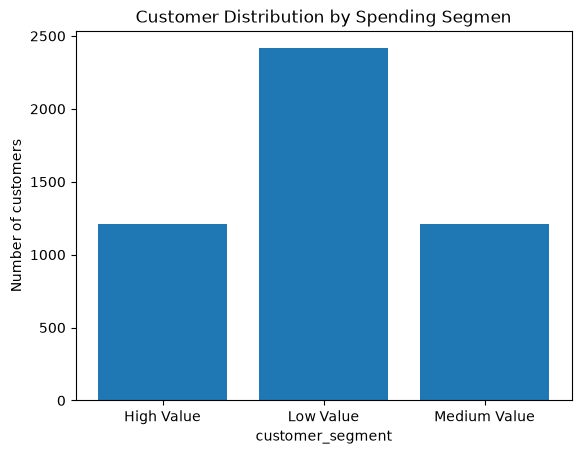

In [91]:
# Create a Bar Chart 

plt.Figure(figsize=(8,5))

plt.bar(segment_summary["customer_segment"],
        segment_summary["customer_count"])

plt.title("Customer Distribution by Spending Segmen")

plt.xlabel("customer_segment")

plt.ylabel("Number of customers")

plt.show()

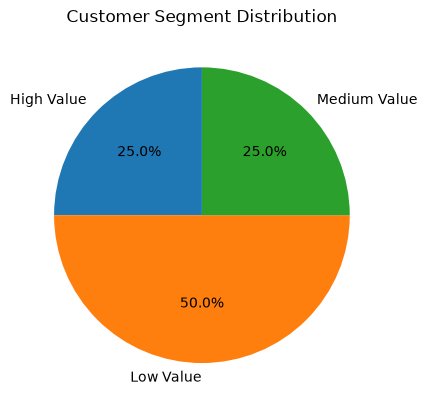

In [92]:
# Create a Pie Chart 

plt.Figure(figsize=(7,7))

plt.pie(
    segment_summary["customer_count"],
    labels = segment_summary["customer_segment"],
    autopct = "%1.1f%%",
    startangle = 90
)

plt.title("Customer Segment Distribution")

plt.show()

# L-32 — Repeat Purchase Analysis

Now let's investigate customer retention behaviour.

Business question: How many customers purchase more than once?

This is important because businesses want to understand whether customers return after their first purchase.

In [93]:
display(customer_orders.head(10))

,customer_id,total_orders
0,C02994,12
1,C01022,11
2,C03973,11
3,C04891,10
4,C02774,10
5,C01927,10
6,C04129,10
7,C01064,10
8,C03255,10
9,C01983,10


In [94]:
customer_orders["purchase_type"] = customer_orders["total_orders"].apply(
    lambda x: "Repeat Customer" if x >= 2 else "One-Time Customer"
)

display(customer_orders.head(10))


,customer_id,total_orders,purchase_type
0,C02994,12,Repeat Customer
1,C01022,11,Repeat Customer
2,C03973,11,Repeat Customer
3,C04891,10,Repeat Customer
4,C02774,10,Repeat Customer
5,C01927,10,Repeat Customer
6,C04129,10,Repeat Customer
7,C01064,10,Repeat Customer
8,C03255,10,Repeat Customer
9,C01983,10,Repeat Customer


In [95]:
# Count each customer group

purchase_summary = (
    customer_orders.groupby("purchase_type")["customer_id"]
    .nunique()
    .reset_index(name = "customer_count")
)

display(purchase_summary)

,purchase_type,customer_count
0,One-Time Customer,585
1,Repeat Customer,4243


In [96]:
customer_orders["customer_id"].nunique()

4828

In [97]:
# Calculate repeat purchase percentages

purchase_summary["customer_percentage"] = (
    (purchase_summary["customer_count"]/purchase_summary["customer_count"].sum())*100
).round(2)
display(purchase_summary)

,purchase_type,customer_count,customer_percentage
0,One-Time Customer,585,12.12
1,Repeat Customer,4243,87.88


In [98]:
# Calculate the repeat customer rate

repeat_customers = customer_orders[
    customer_orders["total_orders"] >= 2
]["customer_id"].nunique()

total_customers = customer_orders["customer_id"].nunique()

repeat_customer_rate = (
    repeat_customers / total_customers * 100
)

print("Repeat customers:", repeat_customers)
print("Total customers:", total_customers)
print("Repeat customer rate:", round(repeat_customer_rate, 2), "%")

Repeat customers: 4243
Total customers: 4828
Repeat customer rate: 87.88 %


# L-33 — Average Orders per Customer

Now let's answer another business question:

On average, how many delivered orders does each customer place?

We already know:
- Total customers with delivered purchases: 4,828
- Repeat customers: 4,243
- One-time customers: 585

But we don't yet know the average number of orders per customer.

In [99]:
# Calculate the average

average_orders_per_customer = (
    customer_orders["total_orders"].mean()
)

print(
    "Average orders per customer:",
    round(average_orders_per_customer, 2)
)

Average orders per customer: 3.51


In [100]:
# Calculate the maximum and minimum

print(
    "Maximum orders:",
    customer_orders["total_orders"].max()
)

print(
    "Minimum orders:",
    customer_orders["total_orders"].min()
)

Maximum orders: 12
Minimum orders: 1


In [101]:
# Check the total number of delivered orders

total_customer_orders = customer_orders["total_orders"].sum()

unique_delivered_orders = delivered_sales["order_id"].nunique()

print("Sum of customer orders:", total_customer_orders)
print("Unique delivered orders:", unique_delivered_orders)
print("Validation:", total_customer_orders == unique_delivered_orders)

Sum of customer orders: 16936
Unique delivered orders: 16936
Validation: True


# L-34 — Customer City Analysis

Now we'll investigate where ShopEase's customers are located and which cities contribute the most revenue.

Business question: Which UAE city generates the highest delivered sales revenue?

One important distinction in your dataset:
- city = customer's registered city.
- shipping_city = destination city for the order.

For this lesson, we'll use city, the customer's registered city.

In [102]:
delivered_sales.head()

,order_item_id,order_id,product_id,quantity,unit_price,discount,gross_amount,discount_amount,total_amount,customer_id,...,cost,profit_per_unit,first_name,last_name,gender,age,city,country,signup_date,order_month
0,OI000001,O00001,P00302,3,752.24,5,2256.72,112.84,2143.88,C02846,...,592.38,159.86,Sara,Thomas,Female,19,Dubai,UAE,2025-09-02,2025-11
1,OI000002,O00001,P00437,1,1608.19,5,1608.19,80.41,1527.78,C02846,...,838.85,769.34,Sara,Thomas,Female,19,Dubai,UAE,2025-09-02,2025-11
2,OI000003,O00002,P00188,4,405.26,10,1621.04,162.10,1458.94,C00980,...,265.84,139.42,Ali,Martin,Male,36,Dubai,UAE,2025-04-08,2025-07
3,OI000004,O00002,P00446,3,328.41,0,985.23,0.00,985.23,C00980,...,193.30,135.11,Ali,Martin,Male,36,Dubai,UAE,2025-04-08,2025-07
4,OI000005,O00002,P00392,5,1258.14,0,6290.70,0.00,6290.70,C00980,...,762.86,495.28,Ali,Martin,Male,36,Dubai,UAE,2025-04-08,2025-07


In [103]:
delivered_sales.columns

Index(['order_item_id', 'order_id', 'product_id', 'quantity', 'unit_price',
       'discount', 'gross_amount', 'discount_amount', 'total_amount',
       'customer_id', 'orders_date', 'order_status', 'shipping_city',
       'product_name', 'category', 'sub_category', 'price', 'cost',
       'profit_per_unit', 'first_name', 'last_name', 'gender', 'age', 'city',
       'country', 'signup_date', 'order_month'],
      dtype='str')

In [104]:
# Inspect the city data

display(
    delivered_sales[
        ["customer_id", "city", "order_id", "total_amount"]
    ].head(10)
)

,customer_id,city,order_id,total_amount
0,C02846,Dubai,O00001,2143.88
1,C02846,Dubai,O00001,1527.78
2,C00980,Dubai,O00002,1458.94
3,C00980,Dubai,O00002,985.23
4,C00980,Dubai,O00002,6290.70
5,C03007,Sharjah,O00003,1206.70
6,C03007,Sharjah,O00003,4459.40
7,C04220,Sharjah,O00004,2573.18
8,C04220,Sharjah,O00004,1168.92
9,C04939,Sharjah,O00005,987.32


In [105]:
print(delivered_sales["city"].unique())

<StringArray>
['Dubai', 'Sharjah', 'Abu Dhabi', 'Al Ain', 'Ajman']
Length: 5, dtype: str


In [106]:
# Calculate revenue by city

city_revenue = (
    delivered_sales.groupby("city")["total_amount"]
    .sum()
    .round(2)
    .reset_index(name="total_revenue")
)

city_revenue = city_revenue.sort_values(
    by = "total_revenue",
    ascending = False 
).reset_index(drop=True)

display(city_revenue.head(10))

,city,total_revenue
0,Dubai,46185326.99
1,Abu Dhabi,29393083.34
2,Sharjah,24565594.57
3,Ajman,12063205.94
4,Al Ain,5833726.44


In [107]:
# Count customers and orders by city

city_analysis = (
    delivered_sales.groupby("city")
    .agg(
        total_revenue = ("total_amount","sum"),
        unique_customers = ("customer_id","nunique"),
        total_orders = ("order_id","nunique")
    )
    .reset_index()
)

city_analysis["total_revenue"] = (
    city_analysis["total_revenue"].round(2)
)

display(city_analysis)

,city,total_revenue,unique_customers,total_orders
0,Abu Dhabi,29393083.34,1229,4222
1,Ajman,12063205.94,501,1706
2,Al Ain,5833726.44,232,875
3,Dubai,46185326.99,1858,6592
4,Sharjah,24565594.57,1008,3541


In [108]:
# Rank cities by revenue

city_analysis = city_analysis.sort_values(
    by="total_revenue",
    ascending=False
).reset_index(drop=True)

display(city_analysis)

,city,total_revenue,unique_customers,total_orders
0,Dubai,46185326.99,1858,6592
1,Abu Dhabi,29393083.34,1229,4222
2,Sharjah,24565594.57,1008,3541
3,Ajman,12063205.94,501,1706
4,Al Ain,5833726.44,232,875


In [109]:
# Validate total revenue

print(
    "City revenue:",
    round(city_analysis["total_revenue"].sum(), 2)
)

print(
    "Delivered revenue:",
    round(delivered_sales["total_amount"].sum(), 2)
)

print(
    "Revenue matches:",
    round(city_analysis["total_revenue"].sum(), 2)
    == round(delivered_sales["total_amount"].sum(), 2)
)

City revenue: 118040937.28
Delivered revenue: 118040937.28
Revenue matches: True


# L-35 — Revenue per Customer by City

Now let's answer a deeper business question:

Does a city generate more revenue because it has more customers, or because each customer spends more?

Dubai has the highest total revenue and customer count. But we need another metric to understand the average revenue generated per customer.

In [110]:
# Calculate revenue per customer

city_analysis["revenue_per_customer"] = (
    city_analysis["total_revenue"]/city_analysis["unique_customers"]
).round(2)

display(city_analysis.head())

,city,total_revenue,unique_customers,total_orders,revenue_per_customer
0,Dubai,46185326.99,1858,6592,24857.55
1,Abu Dhabi,29393083.34,1229,4222,23916.26
2,Sharjah,24565594.57,1008,3541,24370.63
3,Ajman,12063205.94,501,1706,24078.26
4,Al Ain,5833726.44,232,875,25145.37


In [111]:
# Calculate average order value by city
city_analysis["average_order_value"] = (
    city_analysis["total_revenue"]
    /
    city_analysis["total_orders"]
).round(2)

display(city_analysis)

,city,total_revenue,unique_customers,total_orders,revenue_per_customer,average_order_value
0,Dubai,46185326.99,1858,6592,24857.55,7006.27
1,Abu Dhabi,29393083.34,1229,4222,23916.26,6961.89
2,Sharjah,24565594.57,1008,3541,24370.63,6937.47
3,Ajman,12063205.94,501,1706,24078.26,7071.05
4,Al Ain,5833726.44,232,875,25145.37,6667.12


In [112]:
# Sort by revenue per customer

city_analysis = city_analysis.sort_values(
    by="revenue_per_customer",
    ascending=False
).reset_index(drop=True)

display(city_analysis)

,city,total_revenue,unique_customers,total_orders,revenue_per_customer,average_order_value
0,Al Ain,5833726.44,232,875,25145.37,6667.12
1,Dubai,46185326.99,1858,6592,24857.55,7006.27
2,Sharjah,24565594.57,1008,3541,24370.63,6937.47
3,Ajman,12063205.94,501,1706,24078.26,7071.05
4,Abu Dhabi,29393083.34,1229,4222,23916.26,6961.89


# L-36 — Customer Revenue Contribution by City

Now let's investigate another business question:

What percentage of the company's delivered revenue comes from each city?

For example, if Dubai generates AED 50 million out of AED 100 million total revenue, its contribution is 50%.

In [113]:
# Calculate revenue contribution

city_analysis["revenue_contribution"] = (
    city_analysis["total_revenue"]
    /
    city_analysis["total_revenue"].sum()
    *
    100
).round(2)

display(city_analysis)

,city,total_revenue,unique_customers,total_orders,revenue_per_customer,average_order_value,revenue_contribution
0,Al Ain,5833726.44,232,875,25145.37,6667.12,4.94
1,Dubai,46185326.99,1858,6592,24857.55,7006.27,39.13
2,Sharjah,24565594.57,1008,3541,24370.63,6937.47,20.81
3,Ajman,12063205.94,501,1706,24078.26,7071.05,10.22
4,Abu Dhabi,29393083.34,1229,4222,23916.26,6961.89,24.90


In [114]:
# Sort by contribution

city_analysis = city_analysis.sort_values(
    by = "revenue_contribution",
    ascending = False 
).reset_index(drop=True)

display(city_analysis)

,city,total_revenue,unique_customers,total_orders,revenue_per_customer,average_order_value,revenue_contribution
0,Dubai,46185326.99,1858,6592,24857.55,7006.27,39.13
1,Abu Dhabi,29393083.34,1229,4222,23916.26,6961.89,24.90
2,Sharjah,24565594.57,1008,3541,24370.63,6937.47,20.81
3,Ajman,12063205.94,501,1706,24078.26,7071.05,10.22
4,Al Ain,5833726.44,232,875,25145.37,6667.12,4.94


In [115]:
# Validate the percentages

print("Total revenue contribution : ",city_analysis["revenue_contribution"].sum())

Total revenue contribution :  100.0


# L-37 — City-wise Order and Customer Behaviour

Now let's investigate:

How many orders does each customer place on average in each city?

This helps us understand customer purchasing frequency across locations.

In [116]:
# Calculate average orders per customer

city_analysis["orders_per_customer"] = (
    city_analysis["total_orders"]
    / city_analysis["unique_customers"]
).round(2)

display(city_analysis)

,city,total_revenue,unique_customers,total_orders,revenue_per_customer,average_order_value,revenue_contribution,orders_per_customer
0,Dubai,46185326.99,1858,6592,24857.55,7006.27,39.13,3.55
1,Abu Dhabi,29393083.34,1229,4222,23916.26,6961.89,24.90,3.44
2,Sharjah,24565594.57,1008,3541,24370.63,6937.47,20.81,3.51
3,Ajman,12063205.94,501,1706,24078.26,7071.05,10.22,3.41
4,Al Ain,5833726.44,232,875,25145.37,6667.12,4.94,3.77


In [117]:
# Sort by purchasing frequency

city_analysis = city_analysis.sort_values(
    by="orders_per_customer",
    ascending=False
).reset_index(drop=True)

display(city_analysis)

,city,total_revenue,unique_customers,total_orders,revenue_per_customer,average_order_value,revenue_contribution,orders_per_customer
0,Al Ain,5833726.44,232,875,25145.37,6667.12,4.94,3.77
1,Dubai,46185326.99,1858,6592,24857.55,7006.27,39.13,3.55
2,Sharjah,24565594.57,1008,3541,24370.63,6937.47,20.81,3.51
3,Abu Dhabi,29393083.34,1229,4222,23916.26,6961.89,24.90,3.44
4,Ajman,12063205.94,501,1706,24078.26,7071.05,10.22,3.41


# L-38 — City-wise Customer Spending Segmentation

Now we'll combine what we have learned about revenue, customers, and purchasing behaviour.

Business question: Which cities have customers who generate relatively high revenue per customer?

We'll classify cities into three groups based on their revenue per customer:
- High Revenue per Customer
- Medium Revenue per Customer
- Low Revenue per Customer

In [118]:
# Understand the existing values

display(city_analysis[["city","revenue_per_customer"]])

,city,revenue_per_customer
0,Al Ain,25145.37
1,Dubai,24857.55
2,Sharjah,24370.63
3,Abu Dhabi,23916.26
4,Ajman,24078.26


In [119]:
# Calculate thresholds

median_revenue = city_analysis["revenue_per_customer"].median()

print("Median Revenue per Customer : ",median_revenue)

Median Revenue per Customer :  24370.63


In [120]:
# Create city segments

def segment_city(revenue):
    if revenue >= median_revenue * 1.10:
        return "High"
    elif revenue < median_revenue * 0.90:
        return "Low"
    else:
        return "Medium"

city_analysis["customer_spending_segment"] = (
    city_analysis["revenue_per_customer"]
    .apply(segment_city)
)

display(city_analysis)

,city,total_revenue,unique_customers,total_orders,revenue_per_customer,average_order_value,revenue_contribution,orders_per_customer,customer_spending_segment
0,Al Ain,5833726.44,232,875,25145.37,6667.12,4.94,3.77,Medium
1,Dubai,46185326.99,1858,6592,24857.55,7006.27,39.13,3.55,Medium
2,Sharjah,24565594.57,1008,3541,24370.63,6937.47,20.81,3.51,Medium
3,Abu Dhabi,29393083.34,1229,4222,23916.26,6961.89,24.90,3.44,Medium
4,Ajman,12063205.94,501,1706,24078.26,7071.05,10.22,3.41,Medium


# L-39 — Rank Cities by Revenue per Customer

In [121]:
# Create the ranking

city_analysis["revenue_per_customer_rank"] = (
    city_analysis["revenue_per_customer"]
    .rank(method="dense", ascending=False)
    .astype(int)
)

display(
    city_analysis[
        ["city", "revenue_per_customer", "revenue_per_customer_rank"]
    ].sort_values("revenue_per_customer_rank")
)

,city,revenue_per_customer,revenue_per_customer_rank
0,Al Ain,25145.37,1
1,Dubai,24857.55,2
2,Sharjah,24370.63,3
4,Ajman,24078.26,4
3,Abu Dhabi,23916.26,5


# L-40 — City-wise Revenue vs Customer Spending

Let's move to another business question:

Does a city generate more revenue because it has more customers, or because its customers spend more?

We will compare two metrics:
1. unique_customers
2. revenue_per_customer


In [122]:
city_comparison = city_analysis[
    ["city", "unique_customers", "total_revenue", "revenue_per_customer"]
].copy()

display(city_comparison)

,city,unique_customers,total_revenue,revenue_per_customer
0,Al Ain,232,5833726.44,25145.37
1,Dubai,1858,46185326.99,24857.55
2,Sharjah,1008,24565594.57,24370.63
3,Abu Dhabi,1229,29393083.34,23916.26
4,Ajman,501,12063205.94,24078.26


In [125]:
# Calculate each city's customer contribution

city_comparison["customer_contribution"] = (
    city_comparison["unique_customers"]
    /
    city_comparison["unique_customers"].sum()
    * 100 
).round(2)

display(city_comparison)

,city,unique_customers,total_revenue,revenue_per_customer,customer_contribution
0,Al Ain,232,5833726.44,25145.37,4.81
1,Dubai,1858,46185326.99,24857.55,38.48
2,Sharjah,1008,24565594.57,24370.63,20.88
3,Abu Dhabi,1229,29393083.34,23916.26,25.46
4,Ajman,501,12063205.94,24078.26,10.38


In [130]:
# # Calculate each city's revenue contribution

city_comparison["revenue_contribution"] = (
    city_comparison["total_revenue"]
    /
    city_comparison["total_revenue"].sum()
    * 100
).round(2)

display(city_comparison)

,city,unique_customers,total_revenue,revenue_per_customer,customer_contribution,revenue_contribution
0,Al Ain,232,5833726.44,25145.37,4.81,4.94
1,Dubai,1858,46185326.99,24857.55,38.48,39.13
2,Sharjah,1008,24565594.57,24370.63,20.88,20.81
3,Abu Dhabi,1229,29393083.34,23916.26,25.46,24.90
4,Ajman,501,12063205.94,24078.26,10.38,10.22


In [131]:
# Compare revenue and customer contribution

display(
    city_comparison[
        [
            "city",
            "customer_contribution",
            "revenue_contribution",
            "revenue_per_customer"
        ]
    ]
)

,city,customer_contribution,revenue_contribution,revenue_per_customer
0,Al Ain,4.81,4.94,25145.37
1,Dubai,38.48,39.13,24857.55
2,Sharjah,20.88,20.81,24370.63
3,Abu Dhabi,25.46,24.90,23916.26
4,Ajman,10.38,10.22,24078.26


In [133]:
# Now calculate the revenue index

city_comparison["revenue_index"] = (
    city_comparison["revenue_contribution"]
    /
    city_comparison["customer_contribution"]
    * 100
).round(2)

display(
    city_comparison[
        ["city", "customer_contribution",
         "revenue_contribution", "revenue_index"]
    ]
)

,city,customer_contribution,revenue_contribution,revenue_index
0,Al Ain,4.81,4.94,102.70
1,Dubai,38.48,39.13,101.69
2,Sharjah,20.88,20.81,99.66
3,Abu Dhabi,25.46,24.90,97.80
4,Ajman,10.38,10.22,98.46


In [134]:
display(city_comparison)

,city,unique_customers,total_revenue,revenue_per_customer,customer_contribution,revenue_contribution,revenue_index
0,Al Ain,232,5833726.44,25145.37,4.81,4.94,102.70
1,Dubai,1858,46185326.99,24857.55,38.48,39.13,101.69
2,Sharjah,1008,24565594.57,24370.63,20.88,20.81,99.66
3,Abu Dhabi,1229,29393083.34,23916.26,25.46,24.90,97.80
4,Ajman,501,12063205.94,24078.26,10.38,10.22,98.46


# L-42 — Visualizing City Performance

Now we'll create a chart to compare customer contribution and revenue contribution.

This is our first grouped bar chart for this particular analysis.


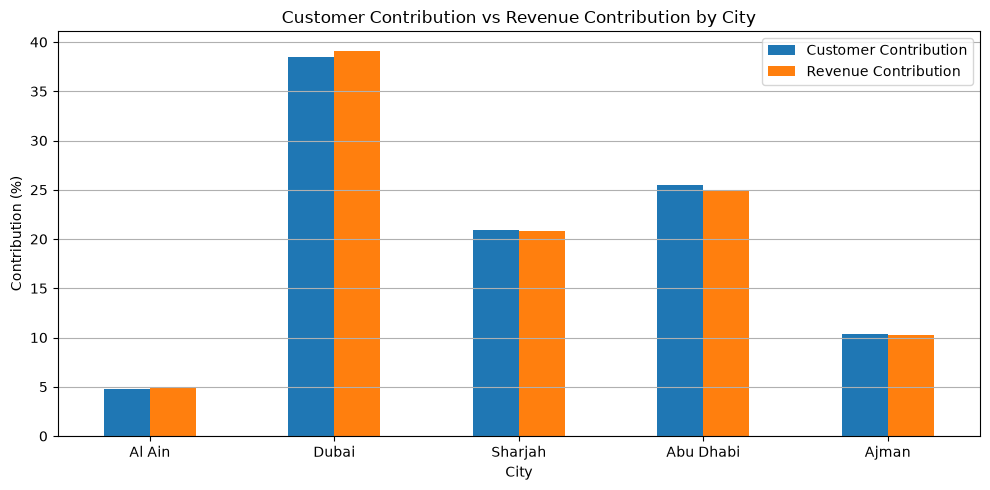

In [140]:
city_comparison.plot(
    x = "city",
    y = ["customer_contribution","revenue_contribution"],
    kind="bar",
    figsize=(10,5)
)

plt.title("Customer Contribution vs Revenue Contribution by City")
plt.xlabel("City")
plt.ylabel("Contribution (%)")
plt.xticks(rotation=0)
plt.grid(True, axis ="y")
plt.legend(["Customer Contribution", "Revenue Contribution"])
plt.tight_layout()
plt.show()

In [150]:
display(city_comparison["city"],city_comparison["customer_contribution"]-city_comparison["revenue_contribution"])

0       Al Ain
1        Dubai
2      Sharjah
3    Abu Dhabi
4        Ajman
Name: city, dtype: str

0   -0.13
1   -0.65
2    0.07
3    0.56
4    0.16
dtype: float64

# L-43 — Product-level Sales Analysis

We've completed a substantial part of customer and city analysis.

Now let's move to a new business area.

Business question: Which products generate the highest delivered revenue?

Imagine an e-commerce company selling:
- Electronics
- Fashion
- Beauty products
- Sports products
- Home products

Management wants to understand which individual products contribute the most revenue.

In [153]:
display(delivered_sales.columns)

Index(['order_item_id', 'order_id', 'product_id', 'quantity', 'unit_price',
       'discount', 'gross_amount', 'discount_amount', 'total_amount',
       'customer_id', 'orders_date', 'order_status', 'shipping_city',
       'product_name', 'category', 'sub_category', 'price', 'cost',
       'profit_per_unit', 'first_name', 'last_name', 'gender', 'age', 'city',
       'country', 'signup_date', 'order_month'],
      dtype='str')

In [151]:
# Understand the product columns

display(
    delivered_sales[
        ["product_id", "product_name", "category", "quantity",
         "unit_price", "total_amount"]
    ].head(10)
)

,product_id,product_name,category,quantity,unit_price,total_amount
0,P00302,Headphones Product 302,Electronics,3,752.24,2143.88
1,P00437,Smartphones Product 437,Electronics,1,1608.19,1527.78
2,P00188,Headphones Product 188,Electronics,4,405.26,1458.94
3,P00446,Accessories Product 446,Electronics,3,328.41,985.23
4,P00392,Skincare Product 392,Beauty,5,1258.14,6290.70
5,P00423,Sportswear Product 423,Sports,2,603.35,1206.70
6,P00086,Shoes Product 86,Fashion,5,1049.27,4459.40
7,P00218,Clothing Product 218,Fashion,3,1009.09,2573.18
8,P00241,Equipment Product 241,Sports,1,1375.20,1168.92
9,P00024,Equipment Product 24,Sports,1,1039.28,987.32


In [155]:
# Calculate revenue by product

product_revenue = (
    delivered_sales.groupby(
        ["product_id","product_name"]
    )["total_amount"]
    .sum()
    .round(2)
    .reset_index(name = "total_revenue")
)

display(product_revenue.head(10))

,product_id,product_name,total_revenue
0,P00001,Skincare Product 1,147254.55
1,P00002,Laptops Product 2,143884.78
2,P00003,Skincare Product 3,162338.81
3,P00004,Skincare Product 4,281134.78
4,P00005,Bags Product 5,223962.06
5,P00006,Haircare Product 6,110573.10
6,P00007,Haircare Product 7,473784.41
7,P00008,Outdoor Product 8,117397.90
8,P00009,Watches Product 9,160790.41
9,P00010,Fitness Product 10,36903.50


In [158]:
# Sort by revenue 

product_revenue = product_revenue.sort_values(
    by = "total_revenue",
    ascending = False
).reset_index(drop = True)

display(product_revenue.head(10))

,product_id,product_name,total_revenue
0,P00377,Outdoor Product 377,572792.00
1,P00326,Shoes Product 326,566392.65
2,P00328,Kitchen Product 328,547271.96
3,P00249,Sportswear Product 249,544881.29
4,P00186,Furniture Product 186,542223.75
5,P00408,Makeup Product 408,538086.80
6,P00051,Bags Product 51,537129.16
7,P00366,Headphones Product 366,536890.69
8,P00455,Decor Product 455,522797.62
9,P00093,Headphones Product 93,522272.41


# Check which products sell the most units

In [ ]:
# Calculate total units sold per product

product_units = (
        delivered_sales.groupby(
        ["product_id","product_name"]
    )["quantity"]
    .sum()
    .round(2)
    .reset_index(name="total_units_sold")
)

display(product_units.head(10))

,product_id,product_name,total_units_sold
0,P00001,Skincare Product 1,314
1,P00002,Laptops Product 2,256
2,P00003,Skincare Product 3,272
3,P00004,Skincare Product 4,255
4,P00005,Bags Product 5,291
5,P00006,Haircare Product 6,294
6,P00007,Haircare Product 7,255
7,P00008,Outdoor Product 8,304
8,P00009,Watches Product 9,234
9,P00010,Fitness Product 10,219


In [161]:
# sort the product units based on the total unit sold 

product_units = product_units.sort_values(
    by="total_units_sold",
    ascending=False
).reset_index(drop=True)

display(product_units.head(10))

,product_id,product_name,total_units_sold
0,P00489,Fitness Product 489,340
1,P00079,Laptops Product 79,326
2,P00020,Fragrance Product 20,326
3,P00081,Skincare Product 81,322
4,P00365,Headphones Product 365,321
5,P00306,Laptops Product 306,320
6,P00182,Clothing Product 182,320
7,P00186,Furniture Product 186,318
8,P00108,Skincare Product 108,315
9,P00001,Skincare Product 1,314


In [162]:
# Check Outdoor Product 377

product_units[
    product_units["product_id"] == "P00377"
]

,product_id,product_name,total_units_sold
17,P00377,Outdoor Product 377,311


# L-44 — Combine product revenue and units sold

Now we'll combine the two DataFrames:
- product_revenue: revenue generated by each product.
- product_units: number of units sold by each product.

In [164]:
# Merge the Dataframes 

product_performance = product_revenue.merge(
    product_units,
    on = ["product_id","product_name"],
    how = "inner",
    validate="one_to_one"
)

display(product_performance.head(10))

,product_id,product_name,total_revenue,total_units_sold
0,P00377,Outdoor Product 377,572792.00,311
1,P00326,Shoes Product 326,566392.65,296
2,P00328,Kitchen Product 328,547271.96,294
3,P00249,Sportswear Product 249,544881.29,296
4,P00186,Furniture Product 186,542223.75,318
5,P00408,Makeup Product 408,538086.80,290
6,P00051,Bags Product 51,537129.16,287
7,P00366,Headphones Product 366,536890.69,284
8,P00455,Decor Product 455,522797.62,283
9,P00093,Headphones Product 93,522272.41,279


In [165]:
# Calculate revenue per unit sold

product_performance["revenue_per_unit"] = (
    product_performance["total_revenue"]
    /
    product_performance["total_units_sold"]
).round(2)

display(product_performance.head(10))

,product_id,product_name,total_revenue,total_units_sold,revenue_per_unit
0,P00377,Outdoor Product 377,572792.00,311,1841.77
1,P00326,Shoes Product 326,566392.65,296,1913.49
2,P00328,Kitchen Product 328,547271.96,294,1861.47
3,P00249,Sportswear Product 249,544881.29,296,1840.82
4,P00186,Furniture Product 186,542223.75,318,1705.11
5,P00408,Makeup Product 408,538086.80,290,1855.47
6,P00051,Bags Product 51,537129.16,287,1871.53
7,P00366,Headphones Product 366,536890.69,284,1890.46
8,P00455,Decor Product 455,522797.62,283,1847.34
9,P00093,Headphones Product 93,522272.41,279,1871.94


In [171]:
product_performance["product_name"].size

500

In [172]:
product_performance = product_performance.sort_values(
    by="revenue_per_unit",
    ascending=False
).reset_index(drop=True)

display(product_performance.head(10))

,product_id,product_name,total_revenue,total_units_sold,revenue_per_unit
0,P00326,Shoes Product 326,566392.65,296,1913.49
1,P00277,Fitness Product 277,476075.64,251,1896.72
2,P00366,Headphones Product 366,536890.69,284,1890.46
3,P00195,Outdoor Product 195,347147.19,184,1886.67
4,P00451,Equipment Product 451,461494.94,245,1883.65
5,P00291,Furniture Product 291,393772.43,210,1875.11
6,P00093,Headphones Product 93,522272.41,279,1871.94
7,P00051,Bags Product 51,537129.16,287,1871.53
8,P00116,Skincare Product 116,442936.27,237,1868.93
9,P00162,Bags Product 162,509499.02,273,1866.30


# L-45 — Identify products with the highest sales volume
Before we finish product analysis, let's compare the top 10 products by revenue with the top 10 by units sold.

You already have product_units and product_performance, so we won't repeat previous calculations.


In [175]:
top_10_units = product_units.head(10)
top_10_units = top_10_units.merge(
    product_revenue,
    on=["product_id","product_name"],
    how="inner",
    validate="one_to_one"
)
print("Products Units")
display(product_units.head(10))
print("Products Revenue")
display(product_revenue.head(10))
print("Top 10 Units")
display(top_10_units)

Products Units


,product_id,product_name,total_units_sold
0,P00489,Fitness Product 489,340
1,P00079,Laptops Product 79,326
2,P00020,Fragrance Product 20,326
3,P00081,Skincare Product 81,322
4,P00365,Headphones Product 365,321
5,P00306,Laptops Product 306,320
6,P00182,Clothing Product 182,320
7,P00186,Furniture Product 186,318
8,P00108,Skincare Product 108,315
9,P00001,Skincare Product 1,314


Products Revenue


,product_id,product_name,total_revenue
0,P00377,Outdoor Product 377,572792.00
1,P00326,Shoes Product 326,566392.65
2,P00328,Kitchen Product 328,547271.96
3,P00249,Sportswear Product 249,544881.29
4,P00186,Furniture Product 186,542223.75
5,P00408,Makeup Product 408,538086.80
6,P00051,Bags Product 51,537129.16
7,P00366,Headphones Product 366,536890.69
8,P00455,Decor Product 455,522797.62
9,P00093,Headphones Product 93,522272.41


Top 10 Units


,product_id,product_name,total_units_sold,total_revenue
0,P00489,Fitness Product 489,340,499234.43
1,P00079,Laptops Product 79,326,334468.71
2,P00020,Fragrance Product 20,326,366303.06
3,P00081,Skincare Product 81,322,514492.06
4,P00365,Headphones Product 365,321,116483.95
5,P00306,Laptops Product 306,320,427554.32
6,P00182,Clothing Product 182,320,402982.62
7,P00186,Furniture Product 186,318,542223.75
8,P00108,Skincare Product 108,315,492280.28
9,P00001,Skincare Product 1,314,147254.55


# L-46 — Product category performance: Revenue vs units

We've already analysed category revenue and category units separately. Now let's bring them together to compare the performance of each category.

In [176]:
# Group revenue and units by category

category_performance = (
    delivered_sales.groupby("category")
    .agg(
        total_revenue = ("total_amount","sum"),
        total_units_sold = ("quantity","sum"),
        unique_products = ("product_id","nunique")
    )
    .reset_index()
)

category_performance[
    ["total_revenue","total_units_sold"]
] =category_performance[
    ["total_revenue","total_units_sold"]
].round(2)

display(category_performance)

,category,total_revenue,total_units_sold,unique_products
0,Beauty,23975841.41,25036,99
1,Electronics,23560697.59,25250,100
2,Fashion,23339171.14,26164,103
3,Home,22348264.76,22148,87
4,Sports,24816962.38,28423,111


In [177]:
display(category_performance)

,category,total_revenue,total_units_sold,unique_products
0,Beauty,23975841.41,25036,99
1,Electronics,23560697.59,25250,100
2,Fashion,23339171.14,26164,103
3,Home,22348264.76,22148,87
4,Sports,24816962.38,28423,111


# L-47 — Average revenue per unit by category
Now let's investigate how much revenue each category generates per unit sold.

This helps us compare categories with different sales volumes.

In [178]:
# Calculate revenue per unit

category_performance["revenue_per_unit"] = (
    category_performance["total_revenue"] 
    /
    category_performance["total_units_sold"]
).round(2)

display(category_performance)

,category,total_revenue,total_units_sold,unique_products,revenue_per_unit
0,Beauty,23975841.41,25036,99,957.65
1,Electronics,23560697.59,25250,100,933.10
2,Fashion,23339171.14,26164,103,892.03
3,Home,22348264.76,22148,87,1009.04
4,Sports,24816962.38,28423,111,873.13


In [179]:
# Sort categories by revenue per unit
category_performance = category_performance.sort_values(
    by="revenue_per_unit",
    ascending=False
).reset_index(drop=True)

display(category_performance)

,category,total_revenue,total_units_sold,unique_products,revenue_per_unit
0,Home,22348264.76,22148,87,1009.04
1,Beauty,23975841.41,25036,99,957.65
2,Electronics,23560697.59,25250,100,933.10
3,Fashion,23339171.14,26164,103,892.03
4,Sports,24816962.38,28423,111,873.13


# L-48 — Visualise category performance

Let's create a grouped bar chart to compare total revenue and units sold by category.

Because revenue and units have very different scales, we'll use two separate charts rather than putting both on the same axis.



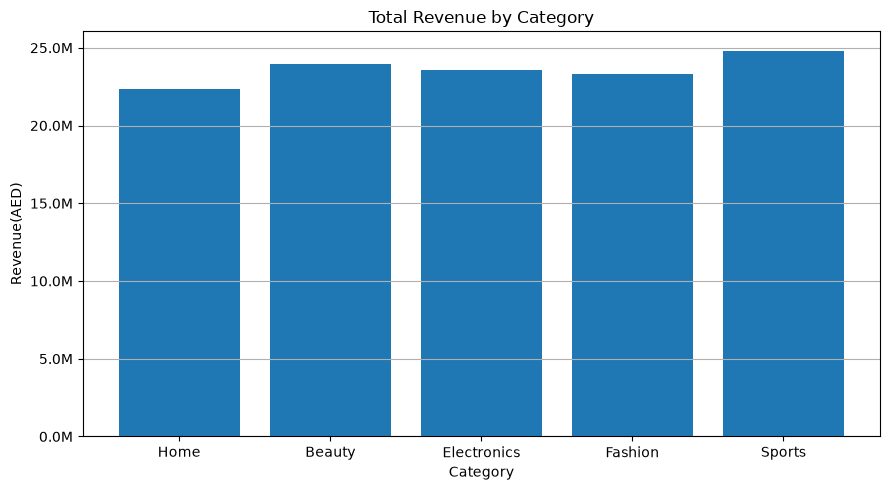

In [187]:
# Total revenue by category
plt.figure(figsize=(9,5))

plt.bar(
    category_performance["category"],
    category_performance["total_revenue"]
)

plt.title("Total Revenue by Category")
plt.xlabel("Category")
plt.ylabel("Revenue(AED)")

# Convert Y-axis labels to millions
plt.gca().yaxis.set_major_formatter(
    FuncFormatter(lambda x,pos:f"{x/1_000_000:.1f}M")
)

plt.grid(True,axis="y")
plt.tight_layout()
plt.show()



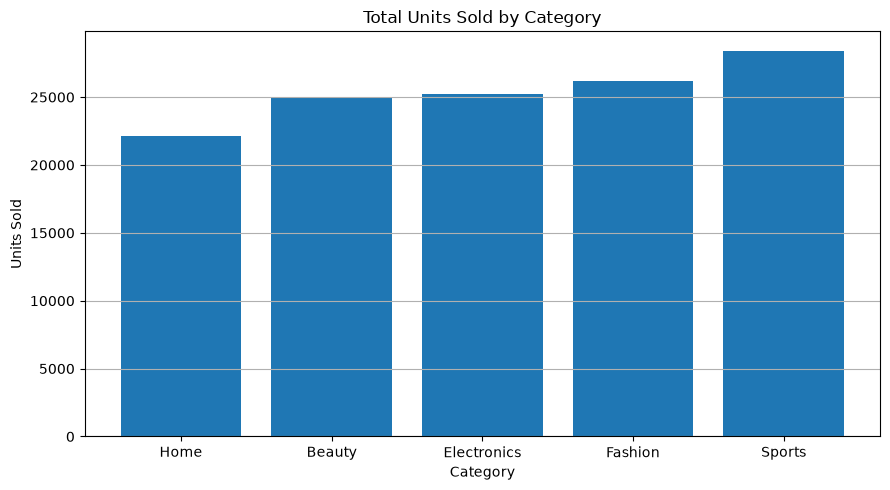

In [194]:
# Total units sold by category

plt.figure(figsize=(9,5))

plt.bar(
    category_performance["category"],
    category_performance["total_units_sold"]
)

plt.title("Total Units Sold by Category")
plt.xlabel("Category")
plt.ylabel("Units Sold")
plt.grid(True,axis="y")
plt.tight_layout()
plt.show()

# L-49 — Monthly product category trends

So far, we've analysed category performance across the entire dataset. Now let's investigate how category revenue changes over time.

Business question: Which product categories generate the most revenue each month?

In [195]:
# Extract the month from the order date

delivered_sales["month"] = (
    delivered_sales["orders_date"].dt.to_period("M")
)

display(
    delivered_sales[
        ["orders_date","category","total_amount","month"]
    ].head(10)
)

,orders_date,category,total_amount,month
0,2025-11-28,Electronics,2143.88,2025-11
1,2025-11-28,Electronics,1527.78,2025-11
2,2025-07-02,Electronics,1458.94,2025-07
3,2025-07-02,Electronics,985.23,2025-07
4,2025-07-02,Beauty,6290.70,2025-07
5,2024-10-29,Sports,1206.70,2024-10
6,2024-10-29,Fashion,4459.40,2024-10
7,2026-02-24,Fashion,2573.18,2026-02
8,2026-02-24,Sports,1168.92,2026-02
9,2025-07-16,Sports,987.32,2025-07


In [199]:
# Group by month and category

monthly_category_sales = (
    delivered_sales.groupby(
        ["month","category"]
    )["total_amount"]
    .sum()
    .reset_index(name="monthly_revenue")
)

display(monthly_category_sales.head(15))

,month,category,monthly_revenue
0,2024-01,Beauty,29050.76
1,2024-01,Electronics,11126.36
2,2024-01,Fashion,2382.57
3,2024-01,Home,25476.17
4,2024-01,Sports,2762.61
5,2024-02,Beauty,66134.49
6,2024-02,Electronics,33532.82
7,2024-02,Fashion,20274.01
8,2024-02,Home,21959.14
9,2024-02,Sports,23408.47


# L-50 — Find the highest-revenue category each month
Now we want to answer:

Which category generated the highest revenue in each month?

In [200]:
display(monthly_category_sales.head(5))

,month,category,monthly_revenue
0,2024-01,Beauty,29050.76
1,2024-01,Electronics,11126.36
2,2024-01,Fashion,2382.57
3,2024-01,Home,25476.17
4,2024-01,Sports,2762.61


In [202]:
# Find the maximum monthly revenue

monthly_category_max = (
    monthly_category_sales.groupby("month")["monthly_revenue"]
    .max()
    .reset_index(name = "highest_revenue")
)

display(monthly_category_max.head(10))

,month,highest_revenue
0,2024-01,29050.76
1,2024-02,66134.49
2,2024-03,57364.42
3,2024-04,141271.56
4,2024-05,170776.47
5,2024-06,188189.62
6,2024-07,227031.04
7,2024-08,264967.21
8,2024-09,328586.12
9,2024-10,312948.11


In [204]:
# Retrieve the category name 

monthly_top_category = monthly_category_sales.merge(
    monthly_category_max,
    left_on = ["month","monthly_revenue"],
    right_on = ["month","highest_revenue"],
    how = "inner"
)

display(monthly_top_category.head(15))

,month,category,monthly_revenue,highest_revenue
0,2024-01,Beauty,29050.76,29050.76
1,2024-02,Beauty,66134.49,66134.49
2,2024-03,Fashion,57364.42,57364.42
3,2024-04,Sports,141271.56,141271.56
4,2024-05,Sports,170776.47,170776.47
5,2024-06,Sports,188189.62,188189.62
6,2024-07,Electronics,227031.04,227031.04
7,2024-08,Sports,264967.21,264967.21
8,2024-09,Sports,328586.12,328586.12
9,2024-10,Fashion,312948.11,312948.11


# L-51 — How often does each category lead?

Now let's find out which category appears most frequently as the highest-revenue category across all 32 months.

Business question: Which category leads in monthly revenue most often?

In [207]:
# Count monthly wins by category
category_monthly_wins = (
    monthly_top_category["category"]
    .value_counts()
    .reset_index()
)

display(category_monthly_wins.head())

category_monthly_wins.columns = ["category","months_as_top_category"]

display(category_monthly_wins)


,category,count
0,Sports,15
1,Beauty,7
2,Fashion,5
3,Electronics,4
4,Home,1


,category,months_as_top_category
0,Sports,15
1,Beauty,7
2,Fashion,5
3,Electronics,4
4,Home,1


In [210]:
# Calculate percentage of months leading

total_months = monthly_top_category["month"].nunique()

print("total_Months : ", total_months)

category_monthly_wins["lead_percentages"] = (
    category_monthly_wins["months_as_top_category"]
    /
    total_months
    * 
    100
).round(2)

display(category_monthly_wins)

total_Months :  32


,category,months_as_top_category,lead_percentages
0,Sports,15,46.88
1,Beauty,7,21.88
2,Fashion,5,15.62
3,Electronics,4,12.50
4,Home,1,3.12


# L-52 — Final EDA: Business insights and recommendations

We're approaching the end of our core EDA. Before moving to SQL and Power BI, let's consolidate what we've discovered.

Here are some of the actual findings from ShopEase:

# Overall delivered sales

## AED 118.04M Total delivered revenue

## 16,936 Delivered orders

## 84.68% Completion rate

## 4,828 Customers with delivered purchases


Category highlights
- Highest total revenue: Sports — AED 24.82M.
- Highest units sold: Sports — 28,423.
- Highest revenue per unit: Home — AED 1,009.04.
- Most frequent monthly leader: Sports — 15 of 32 months.
  
Product highlights
- Highest total revenue: Outdoor Product 377 — AED 572,792.00.
- Highest units sold: Fitness Product 489 — 340 units.
- Highest revenue per unit: Shoes Product 326 — AED 1,913.49.
  
Customer and city highlights
- Highest-revenue city: Dubai — AED 46.19M.
- Highest revenue per customer: Al Ain — AED 25,145.37.
- Repeat customer rate: 87.88%.

